In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
import scipy.cluster.hierarchy as sch

import warnings
warnings.filterwarnings('ignore')


In [2]:
df = pd.read_csv('../dataset/CC_Customer_Dataset.csv')
print('Dimensi data:', df.shape)
df.head()


Dimensi data: (660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [4]:
print('Missing values:')
print(df.isnull().sum())
print('\nJumlah data duplikat:', df.duplicated().sum())


Missing values:
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64

Jumlah data duplikat: 0


In [5]:
features = ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Fitur yang digunakan:', features)
print('Ukuran data setelah scaling:', X_scaled.shape)


Fitur yang digunakan: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
Ukuran data setelah scaling: (660, 5)


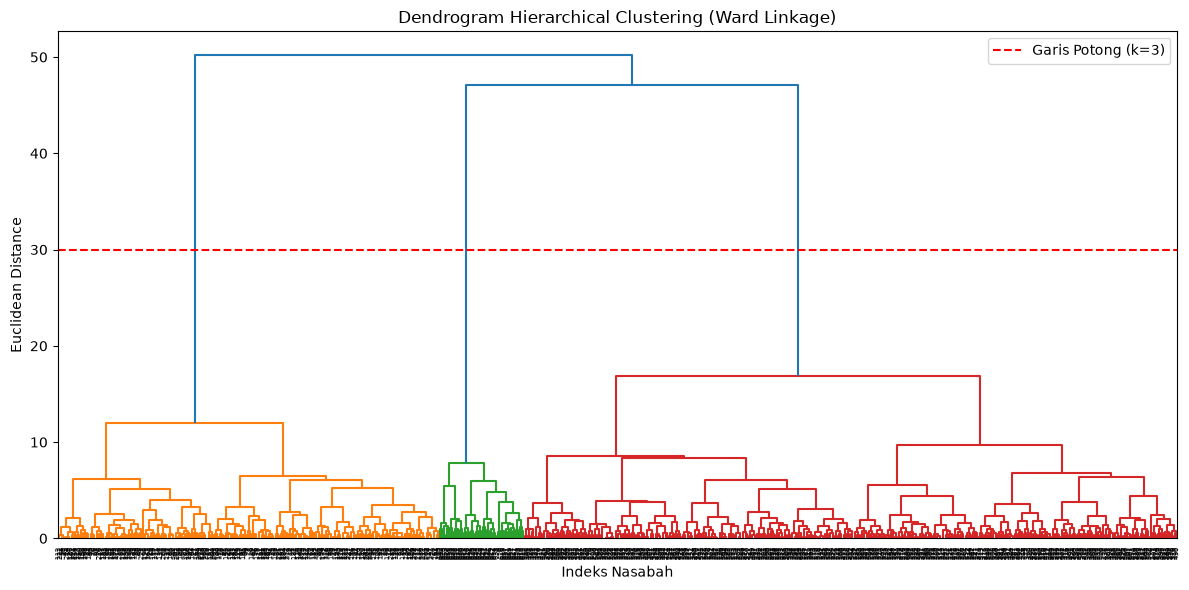

In [6]:
plt.figure(figsize=(12, 6))
dendrogram = sch.dendrogram(sch.linkage(X_scaled, method='ward'))
plt.title('Dendrogram Hierarchical Clustering (Ward Linkage)')
plt.xlabel('Indeks Nasabah')
plt.ylabel('Euclidean Distance')
plt.axhline(y=30, color='r', linestyle='--', label='Garis Potong (k=3)')
plt.legend()
plt.tight_layout()
plt.show()


Berdasarkan dendrogram, jarak vertikal penggabungan terbesar membagi data secara optimal menjadi **k = 3** cluster.

In [7]:
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
clusters = hc.fit_predict(X_scaled)

df['Cluster'] = clusters
print('Distribusi jumlah anggota per cluster:')
print(df['Cluster'].value_counts().sort_index())


Distribusi jumlah anggota per cluster:
Cluster
0    385
1    225
2     50
Name: count, dtype: int64


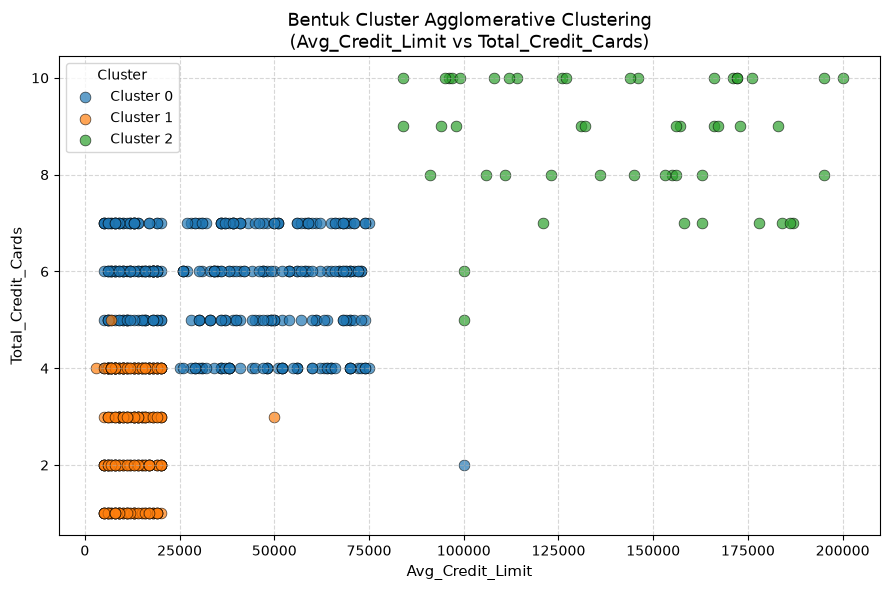

In [8]:
plt.figure(figsize=(9, 6))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
labels = ['Cluster 0', 'Cluster 1', 'Cluster 2']

for i in range(3):
    sub = df[df['Cluster'] == i]
    plt.scatter(
        sub['Avg_Credit_Limit'],
        sub['Total_Credit_Cards'],
        s=60,
        c=colors[i],
        label=labels[i],
        alpha=0.7,
        edgecolors='k',
        linewidth=0.5
    )

plt.title('Bentuk Cluster Agglomerative Clustering\n(Avg_Credit_Limit vs Total_Credit_Cards)', fontsize=13)
plt.xlabel('Avg_Credit_Limit', fontsize=11)
plt.ylabel('Total_Credit_Cards', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Cluster', fontsize=10)
plt.tight_layout()
plt.show()


### Karakteristik dan Bentuk Cluster:
- **Cluster 0:** Nasabah kelas menengah dengan limit kredit berkisar antara 20.000 - 60.000 dan kepemilikan 4 - 7 kartu kredit.
- **Cluster 1:** Nasabah dengan limit kredit rendah (< 20.000) dan kepemilikan 1 - 4 kartu kredit (banyak interaksi melalui call center).
- **Cluster 2:** Nasabah prioritas / bernilai tinggi dengan limit kredit sangat besar (> 80.000 hingga 100.000+) dan kepemilikan 5 - 10 kartu kredit (sangat aktif online).


In [9]:
sil_score = silhouette_score(X_scaled, clusters)
dbi_score = davies_bouldin_score(X_scaled, clusters)

print(f'Silhouette Score     : {sil_score:.4f}')
print(f'Davies-Bouldin Index : {dbi_score:.4f}')


Silhouette Score     : 0.5148
Davies-Bouldin Index : 0.6810


In [10]:
eval_list = []
for k in range(2, 7):
    m = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    labels_k = m.fit_predict(X_scaled)
    eval_list.append({
        'k': k,
        'Silhouette Score': silhouette_score(X_scaled, labels_k),
        'Davies-Bouldin Index': davies_bouldin_score(X_scaled, labels_k)
    })

eval_df = pd.DataFrame(eval_list)
eval_df


,k,Silhouette Score,Davies-Bouldin Index
0,2,0.417704,0.932640
1,3,0.514764,0.680960
2,4,0.348082,1.149303
3,5,0.256918,1.385112
4,6,0.226778,1.410876


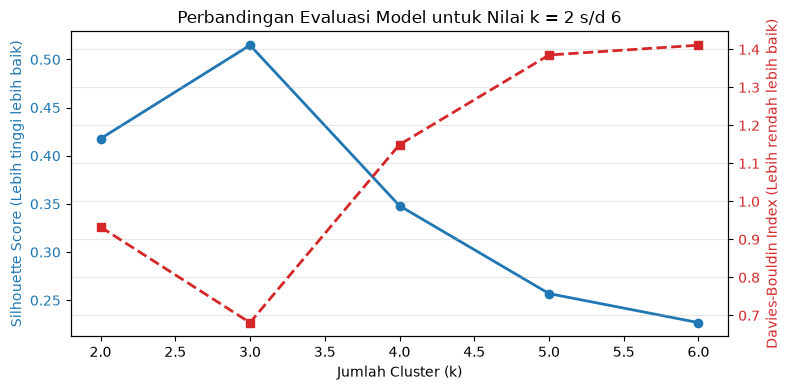

In [11]:
fig, ax1 = plt.subplots(figsize=(8, 4))

color = 'tab:blue'
ax1.set_xlabel('Jumlah Cluster (k)')
ax1.set_ylabel('Silhouette Score (Lebih tinggi lebih baik)', color=color)
ax1.plot(eval_df['k'], eval_df['Silhouette Score'], marker='o', color=color, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Davies-Bouldin Index (Lebih rendah lebih baik)', color=color)
ax2.plot(eval_df['k'], eval_df['Davies-Bouldin Index'], marker='s', color=color, linewidth=2, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Perbandingan Evaluasi Model untuk Nilai k = 2 s/d 6')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:
summary = df.groupby('Cluster')[features].mean().round(2)
summary['Jumlah Nasabah'] = df['Cluster'].value_counts()
summary


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Jumlah Nasabah
Cluster,,,,,,
0,33851.95,5.52,3.49,0.98,1.99,385
1,12151.11,2.42,0.94,3.55,6.86,225
2,141040.00,8.74,0.60,10.90,1.08,50
